# Air Quality Index (AQI) Analysis Mini Project
**Compatible with:** `stations.csv`, `station_day.csv.zip`, and `city_day.csv.zip`

This notebook is adapted for the India air-quality dataset you uploaded. It accepts CSV files and ZIP files containing CSVs. Upload `station_day.csv.zip` or `city_day.csv.zip` for the main analysis; `stations.csv` contains station metadata and is optional.

**Project tasks:** data inspection, cleaning, exploratory data analysis, visualizations, pollutant correlation, AQI prediction using Linear Regression, PCA + Linear Regression, model evaluation, and conclusions.

> Run cells from top to bottom. In Google Colab, upload the relevant dataset file(s) when prompted.

## 1. Import libraries and load dataset

In [2]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import files
    uploaded = files.upload()
    uploaded_names = list(uploaded.keys())
except ImportError:
    uploaded_names = [f for f in os.listdir('.') if f.lower().endswith(('.csv', '.zip'))]
    print("Not running in Colab. Using CSV/ZIP files found in the current folder:", uploaded_names)

def read_csv_or_zip(filename):
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as z:
            csv_names = [n for n in z.namelist() if n.lower().endswith(".csv")]
            if not csv_names:
                raise ValueError(f"No CSV found inside {filename}")
            with z.open(csv_names[0]) as f:
                return pd.read_csv(f)
    return pd.read_csv(filename)

# Prefer city-day or station-day data for analysis; stations.csv is optional metadata.
data_files = [f for f in uploaded_names if f.lower().endswith(('.csv', '.zip'))]
main_candidates = [f for f in data_files if 'city_day' in f.lower() or 'station_day' in f.lower()]
if not main_candidates:
    main_candidates = [f for f in data_files if 'stations' not in f.lower()]
if not main_candidates:
    raise ValueError("Upload city_day.csv.zip or station_day.csv.zip (stations.csv alone is metadata, not daily AQI data).")

main_file = main_candidates[0]
df = read_csv_or_zip(main_file)
print("Loaded:", main_file)
print("Dataset shape:", df.shape)
display(df.head())

Saving city_day.csv to city_day.csv
Loaded: city_day.csv
Dataset shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 2. Inspect and understand the data

In [3]:
print("Columns:")
print(df.columns.tolist())
print("\\nData types and non-null counts:")
df.info()
print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing values"))
print("\\nDuplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)

Columns:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  2

,Missing values
Xylene,18109
PM10,11140
NH3,10328
Toluene,8041
Benzene,5623
AQI,4681
AQI_Bucket,4681
PM2.5,4598
NOx,4185
O3,4022


\nDuplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
City,29531,26,Ahmedabad,2009,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,29531,2009,2020-06-26,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PM2.5,24933.0,NaN,NaN,NaN,67.450578,64.661449,0.04,28.82,48.57,80.59,949.99
PM10,18391.0,NaN,NaN,NaN,118.127103,90.60511,0.01,56.255,95.68,149.745,1000.0
NO,25949.0,NaN,NaN,NaN,17.57473,22.785846,0.02,5.63,9.89,19.95,390.68
NO2,25946.0,NaN,NaN,NaN,28.560659,24.474746,0.01,11.75,21.69,37.62,362.21
NOx,25346.0,NaN,NaN,NaN,32.309123,31.646011,0.0,12.82,23.52,40.1275,467.63
NH3,19203.0,NaN,NaN,NaN,23.483476,25.684275,0.01,8.58,15.85,30.02,352.89
CO,27472.0,NaN,NaN,NaN,2.248598,6.962884,0.0,0.51,0.89,1.45,175.81
SO2,25677.0,NaN,NaN,NaN,14.531977,18.133775,0.01,5.67,9.16,15.22,193.86


## 3. Clean data and prepare date features

In [4]:
df = df.drop_duplicates().copy()

if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["DayOfWeek"] = df["Date"].dt.dayofweek

# Convert pollutant/AQI columns to numeric where possible.
non_numeric = {"City", "StationId", "AQI_Bucket", "Date", "State", "StationName", "Status"}
for col in df.columns:
    if col not in non_numeric:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Drop columns that are entirely empty.
df = df.dropna(axis=1, how="all")
print("Shape after basic cleaning:", df.shape)
display(df.head())

Shape after basic cleaning: (29531, 19)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,Year,Month,DayOfWeek
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN,2015,1,3
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN,2015,1,4
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN,2015,1,5
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN,2015,1,6
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN,2015,1,0


## 4. Visualize AQI distribution

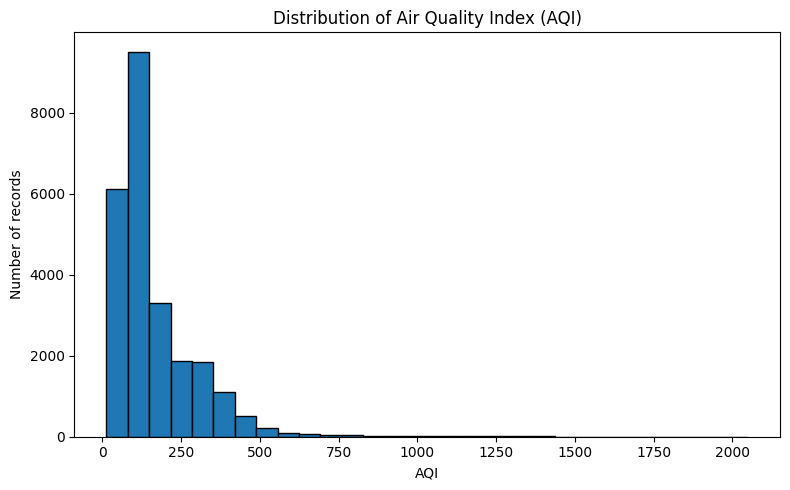

Mean AQI: 166.46
Median AQI: 118.00


In [5]:
if "AQI" in df.columns and df["AQI"].notna().any():
    vals = df["AQI"].dropna()
    plt.figure(figsize=(8, 5))
    plt.hist(vals, bins=30, edgecolor="black")
    plt.xlabel("AQI")
    plt.ylabel("Number of records")
    plt.title("Distribution of Air Quality Index (AQI)")
    plt.tight_layout()
    plt.show()
    print(f"Mean AQI: {vals.mean():.2f}")
    print(f"Median AQI: {vals.median():.2f}")
else:
    print("AQI values are not available in this dataset.")

## 5. Explore pollutant levels

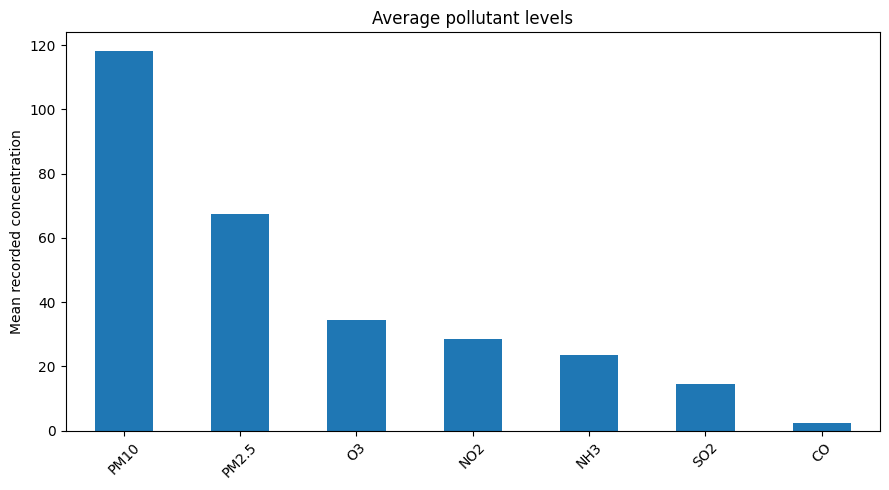

,Mean value
PM10,118.13
PM2.5,67.45
O3,34.49
NO2,28.56
NH3,23.48
SO2,14.53
CO,2.25


In [6]:
pollutants = [c for c in ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3", "NH3"] if c in df.columns and df[c].notna().any()]
if pollutants:
    means = df[pollutants].mean().sort_values(ascending=False)
    plt.figure(figsize=(9, 5))
    means.plot(kind="bar")
    plt.ylabel("Mean recorded concentration")
    plt.title("Average pollutant levels")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    display(means.to_frame("Mean value").round(2))
else:
    print("No recognized pollutant columns with data were found.")

## 6. AQI over time

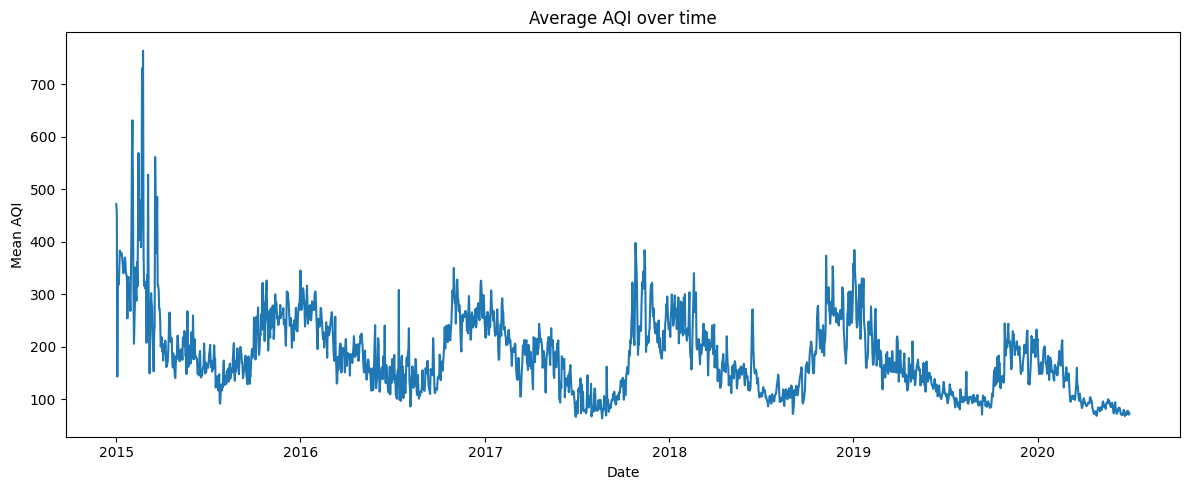

,Mean AQI
Date,
2015-01-01,472.0
2015-01-02,454.0
2015-01-03,143.0
2015-01-04,319.0
2015-01-05,325.0
2015-01-06,318.0
2015-01-07,353.0
2015-01-08,383.0
2015-01-09,375.0


In [7]:
if "Date" in df.columns and "AQI" in df.columns:
    time_df = df[["Date", "AQI"]].dropna().sort_values("Date")
    if not time_df.empty:
        # Daily datasets may contain many stations/cities; show the mean AQI per date.
        daily_aqi = time_df.groupby("Date")["AQI"].mean()
        plt.figure(figsize=(12, 5))
        plt.plot(daily_aqi.index, daily_aqi.values)
        plt.xlabel("Date")
        plt.ylabel("Mean AQI")
        plt.title("Average AQI over time")
        plt.tight_layout()
        plt.show()
        display(daily_aqi.head(10).to_frame("Mean AQI"))
else:
    print("Date or AQI column not available; skipping time-series plot.")

## 7. Correlation between pollutants and AQI

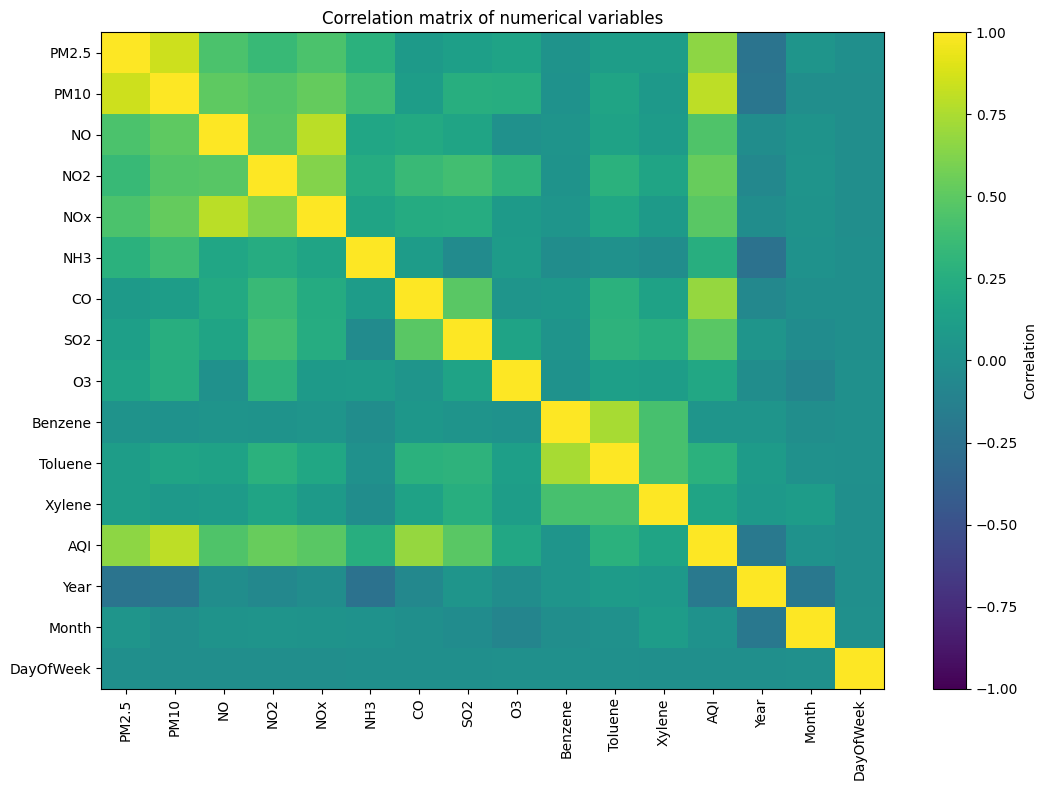

,Correlation with AQI
PM10,0.803313
CO,0.683346
PM2.5,0.659181
NO2,0.537071
SO2,0.490586
NOx,0.486450
NO,0.452191
Toluene,0.279992
NH3,0.252019
O3,0.198991


In [8]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()
if not corr.empty:
    plt.figure(figsize=(11, 8))
    plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    plt.colorbar(label="Correlation")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.title("Correlation matrix of numerical variables")
    plt.tight_layout()
    plt.show()
    if "AQI" in corr.columns:
        display(corr["AQI"].drop("AQI").sort_values(ascending=False).to_frame("Correlation with AQI"))
else:
    print("No numeric columns available for correlation analysis.")

## 8. Predict AQI using Linear Regression and PCA

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target = "AQI"
if target not in df.columns:
    raise ValueError("This file does not contain an AQI column. Use city_day.csv.zip or station_day.csv.zip.")

# Avoid using ID-like/text columns and avoid leakage from AQI category.
excluded = ["AQI", "AQI_Bucket", "Date", "City", "StationId", "StationName", "State", "Status"]
features = df.drop(columns=excluded, errors="ignore")
features = features.select_dtypes(include="number").copy()

# Remove features with >70% missing values and entirely empty columns.
features = features.loc[:, features.isna().mean() <= 0.70]
features = features.dropna(axis=1, how="all")
y = df[target]
valid = y.notna()
X, y = features.loc[valid], y.loc[valid]

if len(X) < 20 or X.shape[1] == 0:
    raise ValueError("Not enough complete AQI records or usable pollutant features for modelling.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Features:", X.columns.tolist())
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

Features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'Year', 'Month', 'DayOfWeek']
Training rows: 19880 | Testing rows: 4970


In [10]:
linear_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
linear_pipeline.fit(X_train, y_train)
linear_pred = linear_pipeline.predict(X_test)
print("Linear Regression model trained.")

Linear Regression model trained.


In [11]:
pca_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("model", LinearRegression())
])
pca_pipeline.fit(X_train, y_train)
pca_pred = pca_pipeline.predict(X_test)
pca_step = pca_pipeline.named_steps["pca"]
print("PCA components retained:", pca_step.n_components_)
print("Variance retained:", round(pca_step.explained_variance_ratio_.sum() * 100, 2), "%")

PCA components retained: 13
Variance retained: 97.35 %


## 9. Evaluate and compare models

In [12]:
def evaluate_model(name, actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(actual, predicted)
    }

results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_pred),
    evaluate_model("PCA + Linear Regression", y_test, pca_pred)
])
display(results.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,30.9985,3511.1984,59.2554,0.8082
1,PCA + Linear Regression,31.4975,3560.5496,59.6703,0.8056


## 10. Actual vs predicted AQI

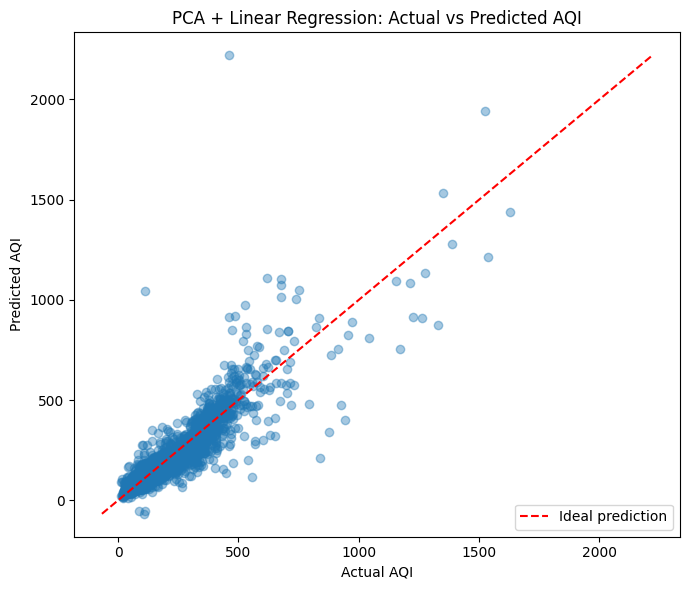

In [13]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, pca_pred, alpha=0.4)
low = min(float(y_test.min()), float(np.min(pca_pred)))
high = max(float(y_test.max()), float(np.max(pca_pred)))
plt.plot([low, high], [low, high], "r--", label="Ideal prediction")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("PCA + Linear Regression: Actual vs Predicted AQI")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Conclusion

In [14]:
best_row = results.sort_values("RMSE").iloc[0]
print("Model with lower RMSE:", best_row["Model"])
print("RMSE:", round(best_row["RMSE"], 3))
print("MAE:", round(best_row["MAE"], 3))
print("R2 Score:", round(best_row["R2 Score"], 3))
print("\\nConclusion:")
print("- The AQI histogram shows the spread of air-quality values in the selected dataset.")
print("- Pollutant summaries and the correlation matrix help explore relationships between pollutants and AQI.")
print("- Linear Regression and PCA + Linear Regression were compared using MAE, RMSE, and R2.")
print("- A lower MAE/RMSE generally indicates smaller prediction errors; R2 should be interpreted alongside these metrics.")
print("- Results reflect historical records in the uploaded dataset, not live AQI readings.")

Model with lower RMSE: Linear Regression
RMSE: 59.255
MAE: 30.999
R2 Score: 0.808
\nConclusion:
- The AQI histogram shows the spread of air-quality values in the selected dataset.
- Pollutant summaries and the correlation matrix help explore relationships between pollutants and AQI.
- Linear Regression and PCA + Linear Regression were compared using MAE, RMSE, and R2.
- A lower MAE/RMSE generally indicates smaller prediction errors; R2 should be interpreted alongside these metrics.
- Results reflect historical records in the uploaded dataset, not live AQI readings.
